# Práctica 3A: Clasificación Zero-shot

**Realizado por: Eduardo Alanís García**


## Instrucciones



1.
   Descomprime el archivo [`datos-3A.zip`](https://aulavirtual.infotec.mx/pluginfile.php/159727/mod_assign/intro/datos-3A.zip?time=1769716657820) que contiene:
   - un directorio de imágenes
   - el archivo miml_labels_1.csv con las etiquetas de las imágenes
2. Carga el modelo CLIP usando la instrucción:
   ```
   model,_,preprocess= open_clip.create_model_and_transforms('ViT-B-32',
   pretrained='laion2b_s34b_b79k')
   ```
3. Usa el modelo para clasificar las imágenes en las categorías:
   ```
   categorias = ["an image of a desert",
                 "an image of a mountain",
                 "an image of a sea",
                 "an image of a sunset"]
   ```
4. Para cada imagen, obtener su encaje y compararlo con los encajes de las categorías y asignarle la más similar.

Nota: Para que sea más rápido el cálculo de los embeddings, activa el entorno de ejecución con una GPU/TPU en colab.

5. Imprime las imágenes (en tamaño 100x100) en donde la clasificación no coincida con la clase verdadera según el archivo miml_labels_1.csv. Incluye la clase predicha por el CLIP y la real.
6. Imprime la clasificación según el modelo de las siguientes imágenes: [‘13.jpg’, ‘405.jpg’, ‘417.jpg’, ‘836.jpg’, ‘1216.jpg’]
7. Escribe una conclusión de la eficacia del modelo en la clasificación.
8. Contesta la evaluación de esta práctica en el Aula Virtual.

### Instalar librería y cargar paquetes


In [29]:
%pip install open_clip_torch


In [30]:
import os
import zipfile
import glob
import torch
import open_clip
import matplotlib.pyplot as plt
from PIL import Image


### Cargar datos desde google drive

In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
direccion = "/content/drive/MyDrive/MCDI-INFOTEC/1. Primer semestre/Manejo y procesamiento de la informacion/Unidad 3/3A. Práctica: Clasificación Zero-shot/datos-3A/"

direccion_imagenes = os.path.join(direccion, "datos", "images")
ruta_etiquetas = os.path.join(direccion, "datos", "miml_labels_1.csv")
images_files = sorted(glob.glob(os.path.join(direccion_imagenes, "*.jpg")))


print("Archivo de etiquetas:", "Existe" if os.path.exists(ruta_etiquetas) else "No existe")
print(f"Número de imágenes: {len(images_files)}")




Archivo de etiquetas: Existe
Número de imágenes: 200


### Leer el archivo con las etiquetas de las imágenes


In [33]:
data = {}

with open(ruta_etiquetas) as f:
  lines = f.readlines()

for l in lines[1:]:
  file_name, desert, mountains, sea, sunset, _ = l.strip().split(",")
  data[file_name] = [desert, mountains, sea, sunset]

print(f"Imágenes con etiquetas: {len(data)}")


Imágenes con etiquetas: 2000


### Cargar el modelo CLIP de openCLIP


In [34]:
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="laion2b_s34b_b79k"
)
model.eval()
tokenizer = open_clip.get_tokenizer("ViT-B-32")

# device = "cuda" if torch.cuda.is_available() else "cpu"
# model = model.to(device)
# print("Dispositivo:", device)


### Crear los embedding para las categorías


In [35]:
categorias = [
    "an image of a desert",
    "an image of a mountain",
    "an image of a sea",
    "an image of a sunset"
]

text = tokenizer(categorias)

with torch.no_grad():
  text_features = model.encode_text(text)
  text_features /= text_features.norm(dim=-1, keepdim=True)


### Crear los embeddings para las imágenes y clasificarlas

Se procesan las imágenes del directorio `datos/images`. Los embeddings de imagen y de texto se normalizan antes de compararlos.


In [36]:
predicciones = {}

for image_file in images_files:
  file_name = os.path.basename(image_file)
  img = Image.open(image_file)
  image = preprocess(img).unsqueeze(0)
  with torch.no_grad():
    image_features = model.encode_image(image)
    image_features /= image_features.norm(dim=-1, keepdim=True)
    similitudes = text_features @ image_features.T

  indice_categoria = torch.argmax(similitudes).numpy()
  predicciones[file_name] = categorias[indice_categoria]
  # print(f"{file_name}: {predicciones[file_name]}")

print(f"Total de imágenes clasificadas: {len(predicciones)}")


Total de imágenes clasificadas: 200


In [37]:
predicciones

{'1.jpg': 'an image of a desert',
 '10.jpg': 'an image of a desert',
 '11.jpg': 'an image of a desert',
 '12.jpg': 'an image of a desert',
 '1201.jpg': 'an image of a sunset',
 '1202.jpg': 'an image of a sunset',
 '1203.jpg': 'an image of a sunset',
 '1204.jpg': 'an image of a sunset',
 '1205.jpg': 'an image of a sunset',
 '1206.jpg': 'an image of a sunset',
 '1207.jpg': 'an image of a sunset',
 '1208.jpg': 'an image of a sunset',
 '1209.jpg': 'an image of a sunset',
 '1210.jpg': 'an image of a sunset',
 '1211.jpg': 'an image of a sunset',
 '1212.jpg': 'an image of a sunset',
 '1213.jpg': 'an image of a sunset',
 '1214.jpg': 'an image of a sunset',
 '1215.jpg': 'an image of a sunset',
 '1216.jpg': 'an image of a sunset',
 '1217.jpg': 'an image of a sunset',
 '1218.jpg': 'an image of a mountain',
 '1219.jpg': 'an image of a sunset',
 '1220.jpg': 'an image of a sunset',
 '1221.jpg': 'an image of a sunset',
 '1222.jpg': 'an image of a sunset',
 '1223.jpg': 'an image of a sunset',
 '1224.j

### Comparar las predicciones con las clases reales


In [44]:
def obtener_clases_reales(nombre_archivo):
  etiquetas = data[nombre_archivo]
  clases_reales = []

  for categoria, etiqueta in zip(categorias, etiquetas):
    if etiqueta == "1":
      clases_reales.append(categoria)

  return clases_reales


mal_clasificadas = []
aciertos = 0

for nombre_archivo in predicciones:
  clases_reales = obtener_clases_reales(nombre_archivo)
  prediccion = predicciones[nombre_archivo]

  if prediccion in clases_reales:
    aciertos += 1
  else:
    mal_clasificadas.append((nombre_archivo, prediccion, clases_reales))

total = len(predicciones)
if total > 0:
  porcentaje = aciertos / total * 100
else:
  porcentaje = 0

print(f"Imágenes con coincidencia: {aciertos} de {total}")
print(f"Porcentaje de coincidencia: {porcentaje:.2f}%")
print(f"Imágenes mal clasificadas: {len(mal_clasificadas)}")


Imágenes con coincidencia: 195 de 200
Porcentaje de coincidencia: 97.50%
Imágenes mal clasificadas: 5


### Imágenes mal clasificadas (100 × 100 píxeles)


Imagen: 1225.jpg | Clases csv: an image of a sunset | Clase predicha por CLIP: an image of a desert


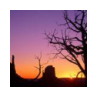

Imagen: 13.jpg | Clases csv: an image of a desert | Clase predicha por CLIP: an image of a mountain


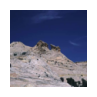

Imagen: 23.jpg | Clases csv: an image of a desert | Clase predicha por CLIP: an image of a mountain


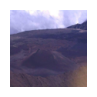

Imagen: 417.jpg | Clases csv: an image of a mountain | Clase predicha por CLIP: an image of a sea


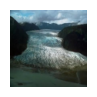

Imagen: 445.jpg | Clases csv: an image of a mountain | Clase predicha por CLIP: an image of a desert


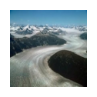

In [43]:
def mostrar_imagen(nombre_archivo):
  ruta_imagen = os.path.join(direccion_imagenes, nombre_archivo)
  img = Image.open(ruta_imagen).resize((100, 100))

  plt.figure(figsize=(1, 1), dpi=100)
  plt.imshow(img)
  plt.axis("off")
  plt.show()


if len(mal_clasificadas) == 0:
  print("No hubo imágenes mal clasificadas.")
else:
  for nombre_archivo, prediccion, clases_reales in mal_clasificadas:
    print(
        f"Imagen: {nombre_archivo} | "
        f"Clases csv: {', '.join(clases_reales)} | "
        f"Clase predicha por CLIP: {prediccion}"
    )
    mostrar_imagen(nombre_archivo)


## Clasificación de las imágenes indicadas


Imagen: 13.jpg | Clases csv: an image of a desert | Clasificación CLIP: an image of a mountain


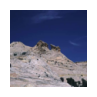

Imagen: 405.jpg | Clases csv: an image of a mountain | Clasificación CLIP: an image of a mountain


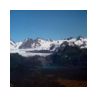

Imagen: 417.jpg | Clases csv: an image of a mountain | Clasificación CLIP: an image of a sea


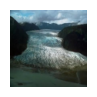

Imagen: 836.jpg | Clases csv: an image of a sea | Clasificación CLIP: an image of a sea


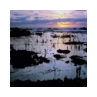

Imagen: 1216.jpg | Clases csv: an image of a sunset | Clasificación CLIP: an image of a sunset


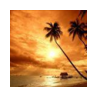

In [42]:
imagenes_prueba = ["13.jpg", "405.jpg", "417.jpg", "836.jpg", "1216.jpg"]

for nombre_archivo in imagenes_prueba:
  prediccion = predicciones[nombre_archivo]
  clases_reales = obtener_clases_reales(nombre_archivo)

  print(
      f"Imagen: {nombre_archivo} | "
      f"Clases csv: {', '.join(clases_reales)} | "
      f"Clasificación CLIP: {prediccion}"
  )
  mostrar_imagen(nombre_archivo)


## Conclusión


En conclusión, CLIP coincidió con al menos una de las categorías reales en 195 de 200 imágenes (97.50%). Este porcentaje resume la eficacia observada en las imágenes analizadas mediante clasificación zero-shot.
Se consideró correcta una predicción cuando coincidió con cualquiera de las etiquetas reales de desierto, montaña, mar u ocaso.

## Contestar la evaluación de esta práctica disponible en el Aula Virtual.

